In [17]:
# ── Install once ──
%pip install pandas numpy scikit-learn matplotlib seaborn plotly xgboost -q
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix,
                              roc_curve, precision_recall_curve, classification_report)


try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import GradientBoostingClassifier
    HAS_XGB = False
    print("xgboost not found — using GradientBoostingClassifier instead. "
          "Run `pip install xgboost` for the real thing.")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')

Note: you may need to restart the kernel to use updated packages.


In [18]:
df = pd.read_csv('../data/ajmal_recruitment_data.csv')
print("Dataset shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

# Dataset overview table
overview = pd.DataFrame({
    'Metric': ['Rows', 'Columns', 'Memory (KB)', 'Duplicate rows', 'Missing values (total)'],
    'Value': [df.shape[0], df.shape[1], round(df.memory_usage(deep=True).sum()/1024, 1),
              df.duplicated().sum(), df.isnull().sum().sum()]
})
display(overview)

Dataset shape: (1500, 11)

First 5 records:


,Age,Gender,EducationLevel,ExperienceYears,PreviousCompanies,DistanceFromCompany,InterviewScore,SkillScore,PersonalityScore,RecruitmentStrategy,HiringDecision
0,26,1,2,0,3,26.783828,48,78,91,1,1
1,39,1,4,12,3,25.862694,35,68,80,2,1
2,48,0,2,3,2,9.920805,20,67,13,2,0
3,34,1,2,5,2,6.407751,36,27,70,3,0
4,30,0,1,6,1,43.105343,23,52,85,2,0


,Metric,Value
0,Rows,1500.0
1,Columns,11.0
2,Memory (KB),129.0
3,Duplicate rows,0.0
4,Missing values (total),0.0


In [19]:
feature_description = pd.DataFrame({
    'Feature': ['Age', 'Gender', 'EducationLevel', 'ExperienceYears', 'PreviousCompanies',
                'DistanceFromCompany', 'InterviewScore', 'SkillScore', 'PersonalityScore',
                'RecruitmentStrategy', 'HiringDecision'],
    'Type': ['Numeric', 'Categorical (protected)', 'Categorical (ordinal)', 'Numeric',
             'Numeric', 'Numeric', 'Numeric', 'Numeric', 'Numeric',
             'Categorical', 'Binary target'],
    'Description': [
        'Applicant age in years',
        'Applicant gender: 0 / 1 (encoding to confirm with data source — treat as sensitive attribute)',
        'Highest education level attained (encoded 1–4)',
        'Years of relevant professional experience',
        'Number of previous employers',
        'Distance in km/miles from applicant to company location',
        'Score awarded at interview stage',
        'Assessed skill/competency score',
        'Assessed personality-fit score',
        'Recruitment channel/strategy used (encoded 1–3)',
        'Outcome: 1 = hired, 0 = not hired (prediction target)'
    ]
})
display(feature_description)

# Quick sanity check on categorical encodings
for col in ['Gender', 'EducationLevel', 'RecruitmentStrategy', 'HiringDecision']:
    print(f"{col}: {sorted(df[col].unique())}")

,Feature,Type,Description
0,Age,Numeric,Applicant age in years
1,Gender,Categorical (protected),Applicant gender: 0 / 1 (encoding to confirm w...
2,EducationLevel,Categorical (ordinal),Highest education level attained (encoded 1–4)
3,ExperienceYears,Numeric,Years of relevant professional experience
4,PreviousCompanies,Numeric,Number of previous employers
5,DistanceFromCompany,Numeric,Distance in km/miles from applicant to company...
6,InterviewScore,Numeric,Score awarded at interview stage
7,SkillScore,Numeric,Assessed skill/competency score
8,PersonalityScore,Numeric,Assessed personality-fit score
9,RecruitmentStrategy,Categorical,Recruitment channel/strategy used (encoded 1–3)


Gender: [np.int64(0), np.int64(1)]
EducationLevel: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
RecruitmentStrategy: [np.int64(1), np.int64(2), np.int64(3)]
HiringDecision: [np.int64(0), np.int64(1)]


In [20]:
missing = df.isnull().sum()
missing_table = pd.DataFrame({'Missing Values': missing, 'Percentage': (missing/len(df)*100).round(2)})
display(missing_table)

duplicate_count = df.duplicated().sum()
print(f"Duplicate rows: {duplicate_count}")

# Validate numeric ranges
print(df.describe().T)

# Confirm dtypes
print(df.dtypes)

# Drop duplicates if any exist
df_clean = df.drop_duplicates().reset_index(drop=True)

# Save cleaned dataset
df_clean.to_csv('recruitment_data_clean.csv', index=False)
print(f"Clean dataset saved: {df_clean.shape}")

,Missing Values,Percentage
Age,0,0.0
Gender,0,0.0
EducationLevel,0,0.0
ExperienceYears,0,0.0
PreviousCompanies,0,0.0
DistanceFromCompany,0,0.0
InterviewScore,0,0.0
SkillScore,0,0.0
PersonalityScore,0,0.0
RecruitmentStrategy,0,0.0


Duplicate rows: 0
                      count       mean        std        min        25%  \
Age                  1500.0  35.148667   9.252728  20.000000  27.000000   
Gender               1500.0   0.492000   0.500103   0.000000   0.000000   
EducationLevel       1500.0   2.188000   0.862449   1.000000   2.000000   
ExperienceYears      1500.0   7.694000   4.641414   0.000000   4.000000   
PreviousCompanies    1500.0   3.002000   1.410670   1.000000   2.000000   
DistanceFromCompany  1500.0  25.505379  14.567151   1.031376  12.838851   
InterviewScore       1500.0  50.564000  28.626215   0.000000  25.000000   
SkillScore           1500.0  51.116000  29.353563   0.000000  25.750000   
PersonalityScore     1500.0  49.387333  29.353201   0.000000  23.000000   
RecruitmentStrategy  1500.0   1.893333   0.689642   1.000000   1.000000   
HiringDecision       1500.0   0.310000   0.462647   0.000000   0.000000   

                           50%        75%         max  
Age                  35.0

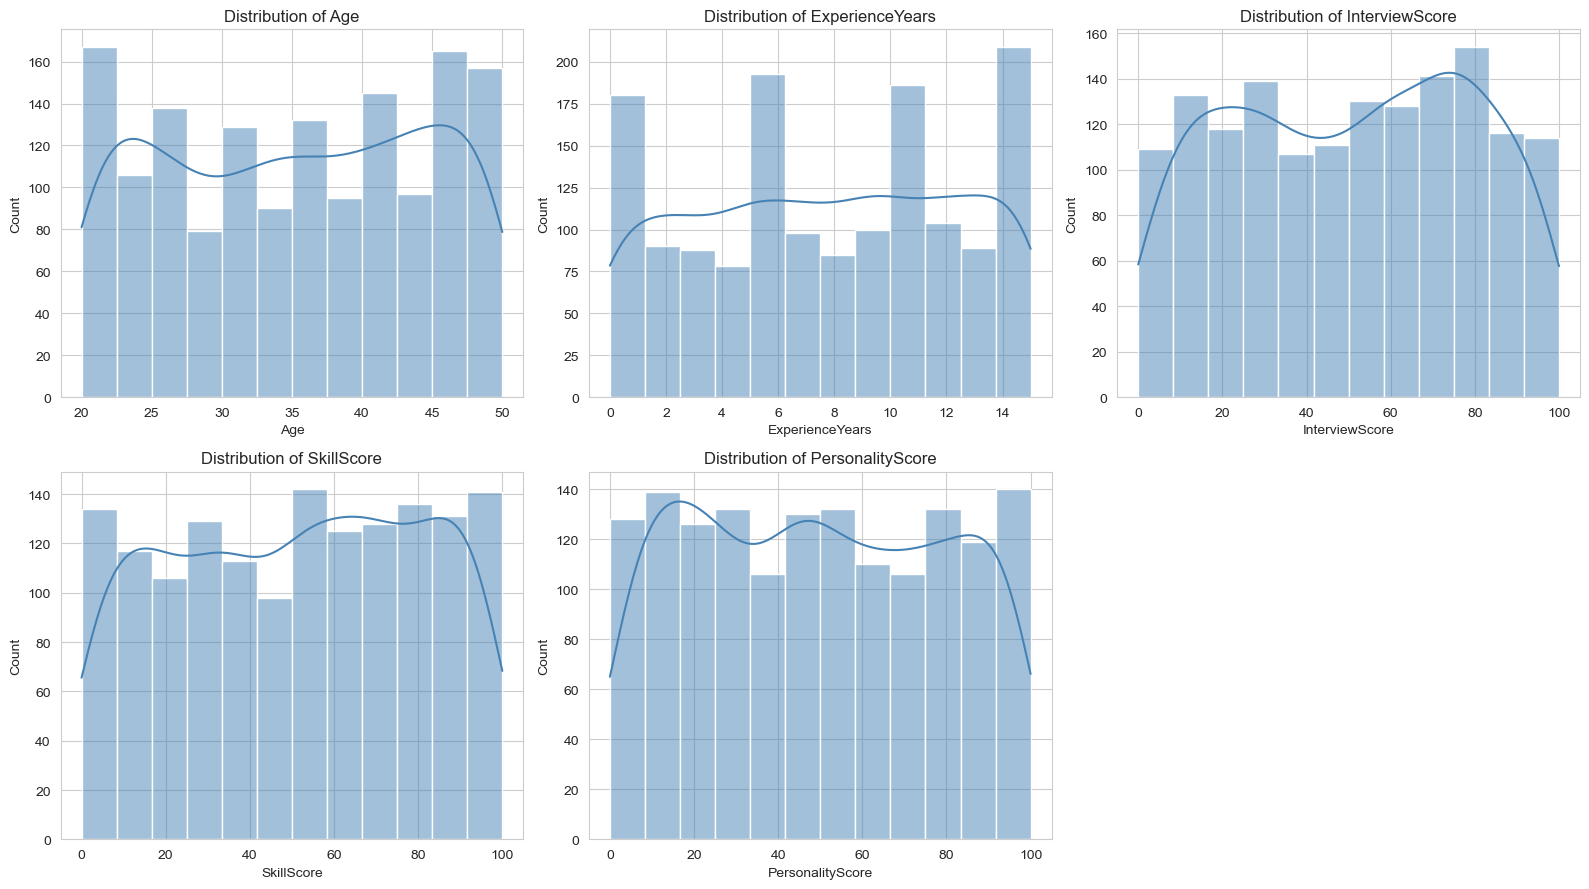

In [21]:
# --- Distribution plots ---
num_features = ['Age', 'ExperienceYears', 'InterviewScore', 'SkillScore', 'PersonalityScore']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), num_features):
    sns.histplot(df_clean[col], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {col}')
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.savefig('eda_distributions.png', dpi=150)
plt.show()



C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\1219356730.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_clean, ax=ax, palette='viridis')
C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\1219356730.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_clean, ax=ax, palette='viridis')
C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\1219356730.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=df_clean, ax=ax, palette='viridis')
C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31

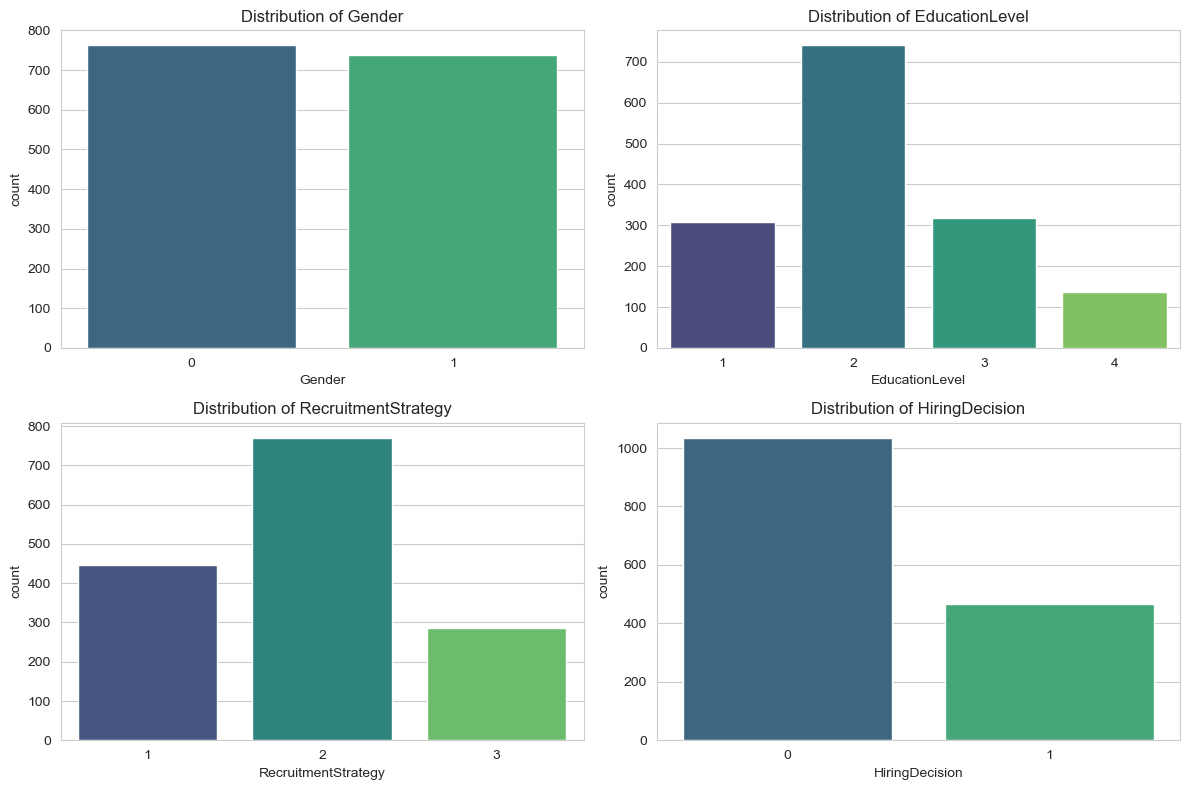

In [22]:


# --- Categorical charts ---
cat_features = ['Gender', 'EducationLevel', 'RecruitmentStrategy', 'HiringDecision']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cat_features):
    sns.countplot(x=col, data=df_clean, ax=ax, palette='viridis')
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.savefig('eda_categorical.png', dpi=150)
plt.show()



C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\3425702064.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HiringDecision', y=col, data=df_clean, ax=ax, palette='Set2')
C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\3425702064.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HiringDecision', y=col, data=df_clean, ax=ax, palette='Set2')
C:\Users\ajuajmal\AppData\Local\Temp\ipykernel_31104\3425702064.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='HiringDecision', y=col, data=df_clean, ax=ax, palette='Set2')
C:\U

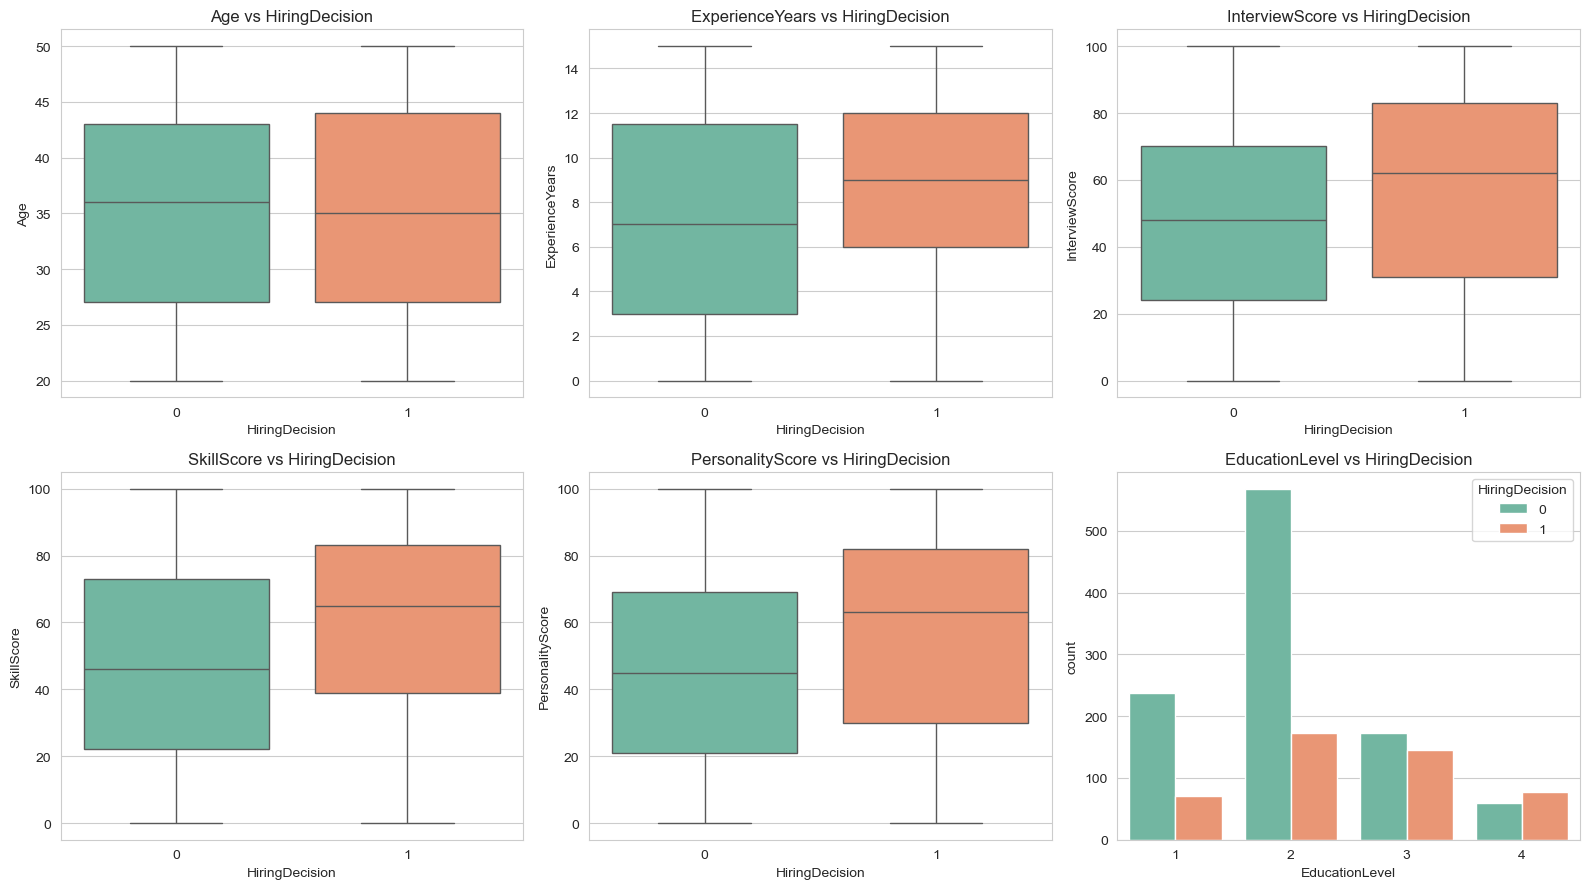

In [23]:


# --- Relationship plots vs HiringDecision ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), num_features):
    sns.boxplot(x='HiringDecision', y=col, data=df_clean, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs HiringDecision')
for ax, col in zip(axes.flatten()[len(num_features):], ['EducationLevel', 'RecruitmentStrategy']):
    sns.countplot(x=col, hue='HiringDecision', data=df_clean, ax=ax, palette='Set2')
    ax.set_title(f'{col} vs HiringDecision')
plt.tight_layout()
plt.savefig('eda_relationships.png', dpi=150)
plt.show()





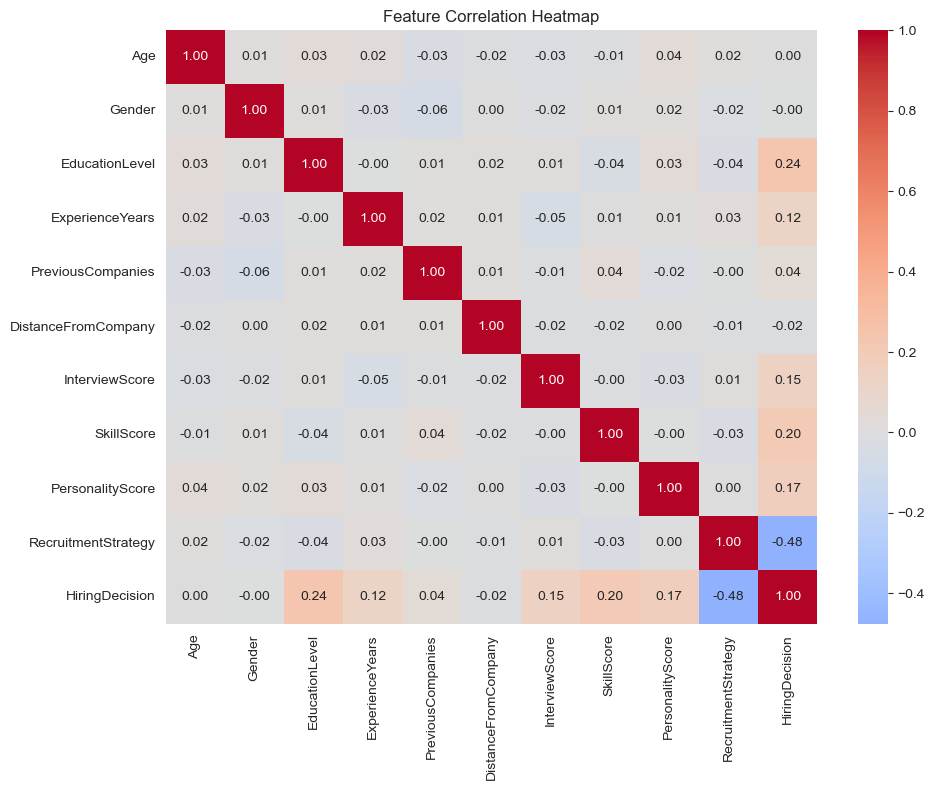

In [24]:

   

# --- Correlation heatmap ---
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('eda_correlation.png', dpi=150)
plt.show()



In [25]:


# --- Statistical summary table ---
summary_stats = df_clean.describe().T
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
Age,1500.0,35.148667,9.252728,20.000000,27.000000,35.000000,43.000000,50.000000
Gender,1500.0,0.492000,0.500103,0.000000,0.000000,0.000000,1.000000,1.000000
EducationLevel,1500.0,2.188000,0.862449,1.000000,2.000000,2.000000,3.000000,4.000000
ExperienceYears,1500.0,7.694000,4.641414,0.000000,4.000000,8.000000,12.000000,15.000000
PreviousCompanies,1500.0,3.002000,1.410670,1.000000,2.000000,3.000000,4.000000,5.000000
DistanceFromCompany,1500.0,25.505379,14.567151,1.031376,12.838851,25.502239,37.737996,50.992462
InterviewScore,1500.0,50.564000,28.626215,0.000000,25.000000,52.000000,75.000000,100.000000
SkillScore,1500.0,51.116000,29.353563,0.000000,25.750000,53.000000,76.000000,100.000000
PersonalityScore,1500.0,49.387333,29.353201,0.000000,23.000000,49.000000,76.000000,100.000000
RecruitmentStrategy,1500.0,1.893333,0.689642,1.000000,1.000000,2.000000,2.000000,3.000000


In [26]:
TARGET = 'HiringDecision'
PROTECTED = 'Gender'    # sensitive attribute for fairness auditing

X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# Keep the protected attribute for the TEST set aside for fairness evaluation
gender_test = X_test[PROTECTED].copy()

# Scale numeric features
scaler = StandardScaler()
feature_cols = X.columns.tolist()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[feature_cols] = scaler.fit_transform(X_train[feature_cols])
X_test_scaled[feature_cols] = scaler.transform(X_test[feature_cols])

split_summary = pd.DataFrame({
    'Set': ['Train', 'Test'],
    'Rows': [len(X_train), len(X_test)],
    'Hiring Rate (%)': [round(y_train.mean()*100, 2), round(y_test.mean()*100, 2)]
})
display(split_summary)

,Set,Rows,Hiring Rate (%)
0,Train,1125,31.02
1,Test,375,30.93


In [27]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}
if HAS_XGB:
    models['XGBoost'] = XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE)
else:
    models['Gradient Boosting'] = GradientBoostingClassifier(random_state=RANDOM_STATE)

trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    trained_models[name] = model
    predictions[name] = {'pred': pred, 'proba': proba}
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
XGBoost trained.


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.8613,0.8265,0.6983,0.7570,0.8792
Decision Tree,0.9120,0.9109,0.7931,0.8479,0.8955
Random Forest,0.9227,0.9579,0.7845,0.8626,0.9150
XGBoost,0.9173,0.9208,0.8017,0.8571,0.9140


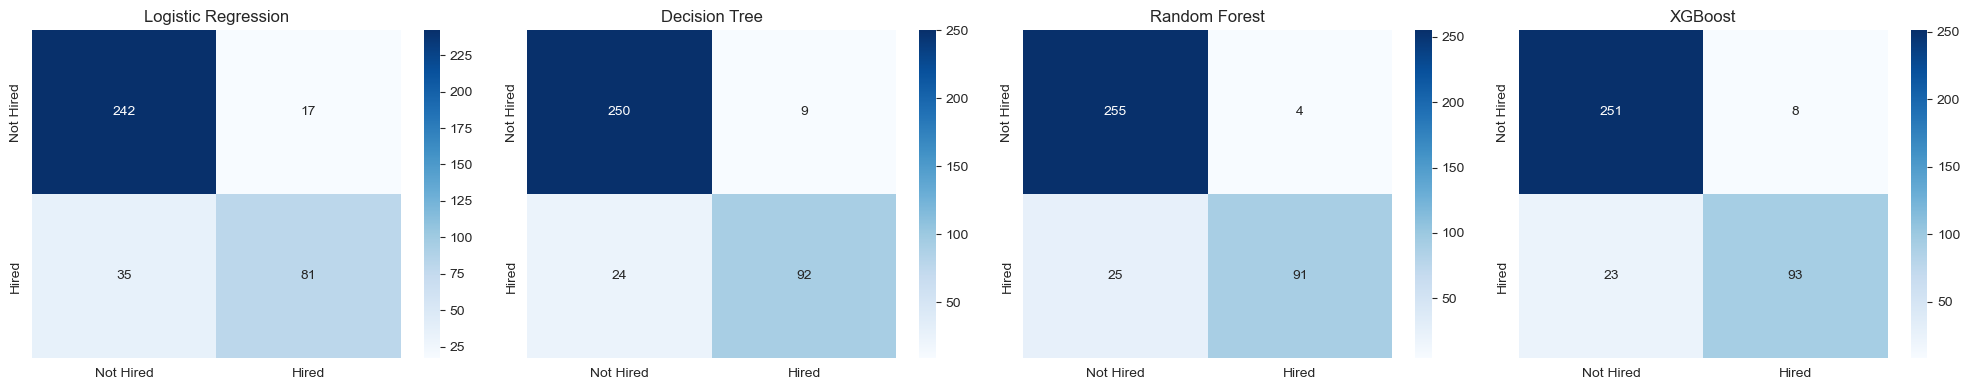

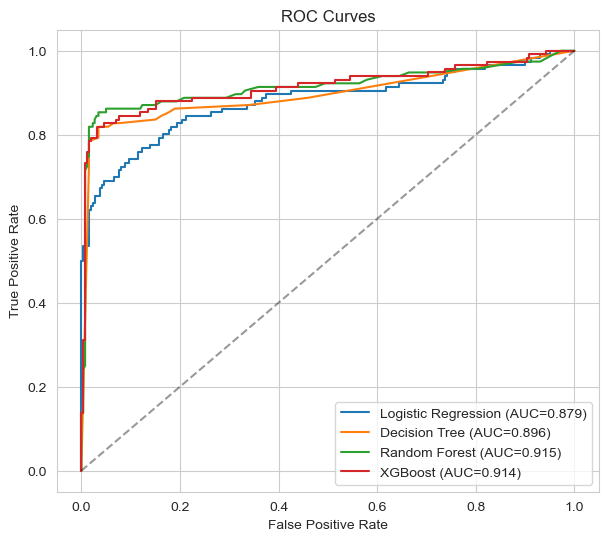

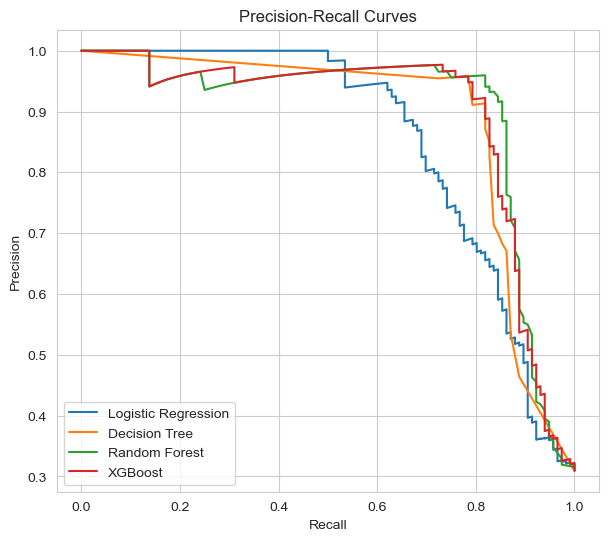

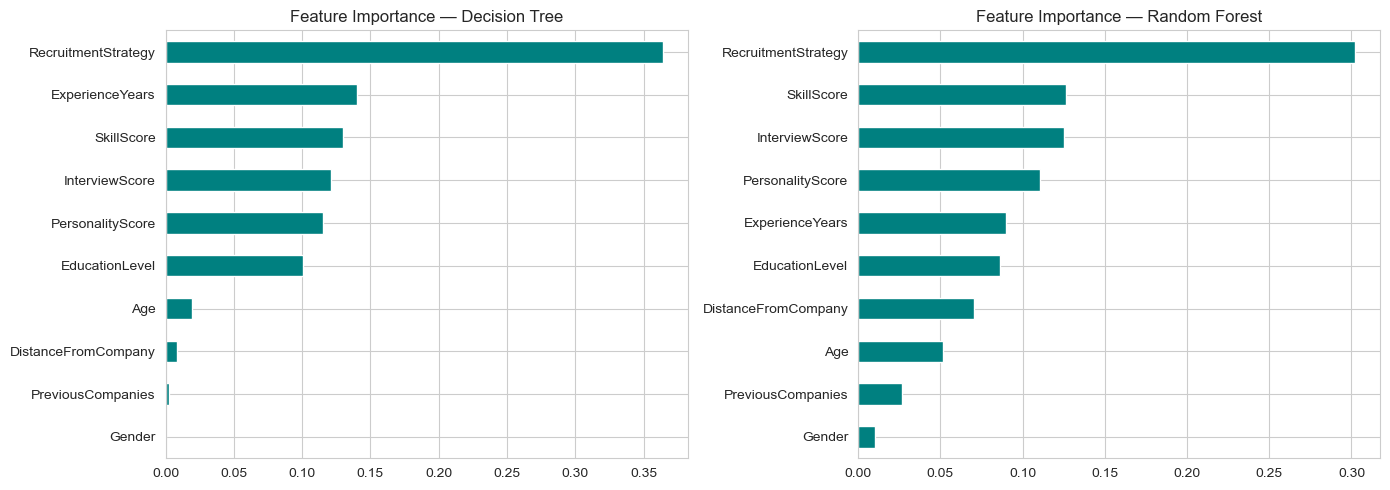

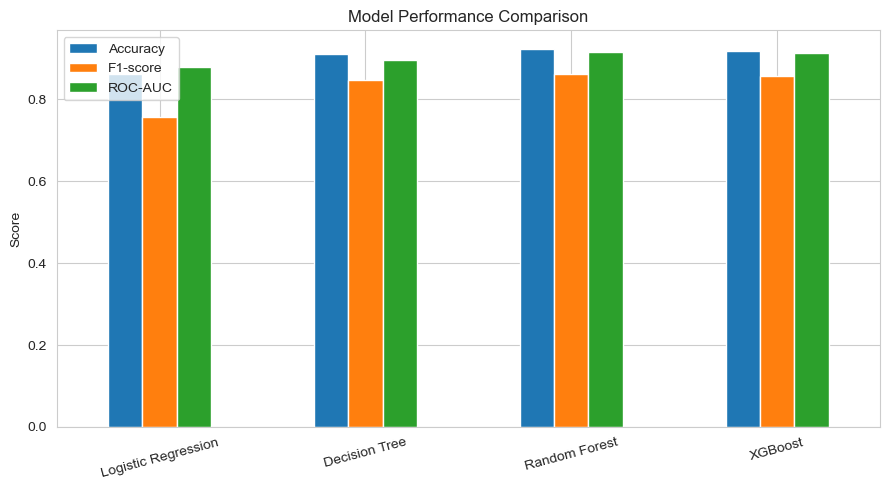

In [28]:
performance = {}
for name, p in predictions.items():
    performance[name] = {
        'Accuracy': accuracy_score(y_test, p['pred']),
        'Precision': precision_score(y_test, p['pred']),
        'Recall': recall_score(y_test, p['pred']),
        'F1-score': f1_score(y_test, p['pred']),
        'ROC-AUC': roc_auc_score(y_test, p['proba']),
    }

performance_df = pd.DataFrame(performance).T.round(4)
display(performance_df)

# --- Confusion matrices ---
fig, axes = plt.subplots(1, len(models), figsize=(5*len(models), 4))
for ax, (name, p) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, p['pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Hired', 'Hired'], yticklabels=['Not Hired', 'Hired'])
    ax.set_title(name)
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

# --- ROC curves ---
plt.figure(figsize=(7, 6))
for name, p in predictions.items():
    fpr, tpr, _ = roc_curve(y_test, p['proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p['proba']):.3f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend()
plt.savefig('roc_curves.png', dpi=150)
plt.show()

# --- Precision-Recall curves ---
plt.figure(figsize=(7, 6))
for name, p in predictions.items():
    prec, rec, _ = precision_recall_curve(y_test, p['proba'])
    plt.plot(rec, prec, label=name)
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curves'); plt.legend()
plt.savefig('pr_curves.png', dpi=150)
plt.show()

# --- Feature importance (tree-based models) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tree_models = {k: v for k, v in trained_models.items() if hasattr(v, 'feature_importances_')}
for ax, (name, model) in zip(axes, list(tree_models.items())[:2]):
    imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
    imp.plot(kind='barh', ax=ax, color='teal')
    ax.set_title(f'Feature Importance — {name}')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

# --- Model comparison chart ---
performance_df[['Accuracy', 'F1-score', 'ROC-AUC']].plot(kind='bar', figsize=(9, 5))
plt.title('Model Performance Comparison'); plt.ylabel('Score'); plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()


=== Logistic Regression — group breakdown by Gender ===


,n,selection_rate,accuracy,precision,recall (TPR),FPR,F1
0,185.0,0.2324,0.8595,0.8140,0.6604,0.0606,0.7292
1,190.0,0.2895,0.8632,0.8364,0.7302,0.0709,0.7797



=== Decision Tree — group breakdown by Gender ===


,n,selection_rate,accuracy,precision,recall (TPR),FPR,F1
0,185.0,0.2324,0.8811,0.8605,0.6981,0.0455,0.7708
1,190.0,0.3053,0.9421,0.9483,0.8730,0.0236,0.9091



=== Random Forest — group breakdown by Gender ===


,n,selection_rate,accuracy,precision,recall (TPR),FPR,F1
0,185.0,0.2216,0.9135,0.9512,0.7358,0.0152,0.8298
1,190.0,0.2842,0.9316,0.9630,0.8254,0.0157,0.8889



=== XGBoost — group breakdown by Gender ===


,n,selection_rate,accuracy,precision,recall (TPR),FPR,F1
0,185.0,0.2378,0.8973,0.8864,0.7358,0.0379,0.8041
1,190.0,0.3000,0.9368,0.9474,0.8571,0.0236,0.9000



=== Fairness metric comparison across models ===


,Demographic Parity Difference,Demographic Parity Ratio,Disparate Impact Ratio,Equal Opportunity Difference,Equalized Odds Difference,Error Rate Difference
Logistic Regression,0.0570,0.8029,0.8029,0.0698,0.0698,0.0037
Decision Tree,0.0728,0.7614,0.7614,0.1749,0.1749,0.0610
Random Forest,0.0626,0.7798,0.7798,0.0895,0.0895,0.0181
XGBoost,0.0622,0.7928,0.7928,0.1213,0.1213,0.0395


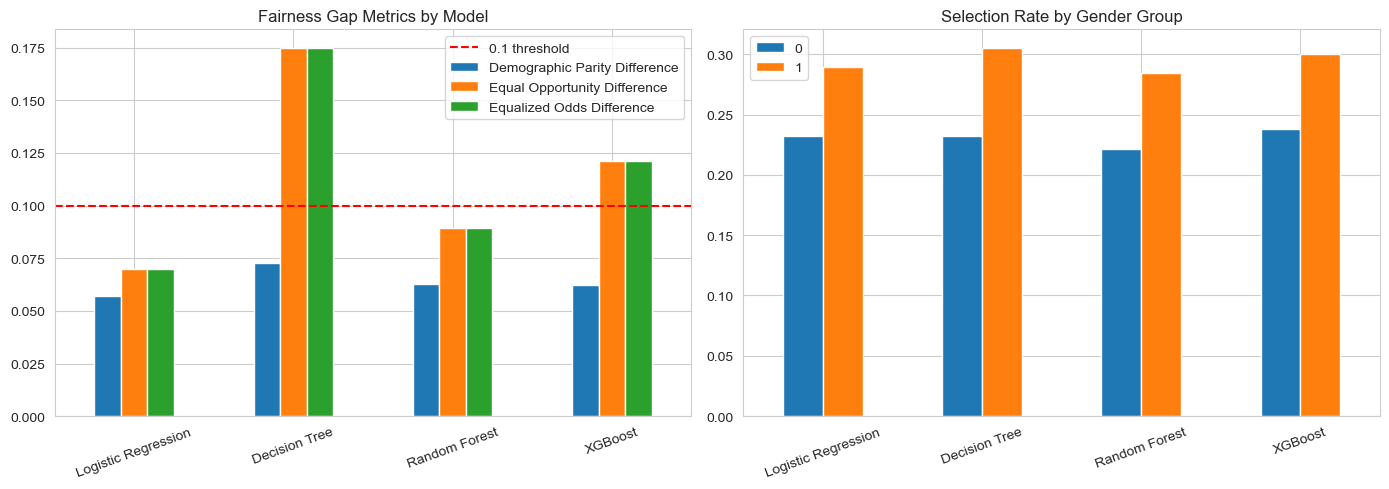

In [29]:
def fairness_metrics(y_true, y_pred, sensitive_attr):
    """
    Computes group-wise performance and standard group-fairness metrics
    across the two Gender groups in the test set.
    """
    data = pd.DataFrame({'y_true': y_true.values, 'y_pred': y_pred,
                          'group': sensitive_attr.values})
    groups = sorted(data['group'].unique())
    group_stats = {}

    for g in groups:
        sub = data[data['group'] == g]
        tp = ((sub.y_true == 1) & (sub.y_pred == 1)).sum()
        fn = ((sub.y_true == 1) & (sub.y_pred == 0)).sum()
        fp = ((sub.y_true == 0) & (sub.y_pred == 1)).sum()
        tn = ((sub.y_true == 0) & (sub.y_pred == 0)).sum()

        group_stats[g] = {
            'n': len(sub),
            'selection_rate': sub.y_pred.mean(),
            'accuracy': (tp + tn) / len(sub),
            'precision': tp / (tp + fp) if (tp + fp) > 0 else np.nan,
            'recall (TPR)': tp / (tp + fn) if (tp + fn) > 0 else np.nan,
            'FPR': fp / (fp + tn) if (fp + tn) > 0 else np.nan,
            'F1': f1_score(sub.y_true, sub.y_pred, zero_division=0),
        }

    group_df = pd.DataFrame(group_stats).T

    sel = group_df['selection_rate']
    tpr = group_df['recall (TPR)']
    fpr = group_df['FPR']
    err = 1 - group_df['accuracy']

    metrics = {
        'Demographic Parity Difference': sel.max() - sel.min(),
        'Demographic Parity Ratio': sel.min() / sel.max() if sel.max() > 0 else np.nan,
        'Disparate Impact Ratio': sel.min() / sel.max() if sel.max() > 0 else np.nan,
        'Equal Opportunity Difference': tpr.max() - tpr.min(),
        'Equalized Odds Difference': max(tpr.max() - tpr.min(), fpr.max() - fpr.min()),
        'Error Rate Difference': err.max() - err.min(),
    }
    return group_df, metrics

fairness_results = {}
group_breakdowns = {}

for name, p in predictions.items():
    group_df, metrics = fairness_metrics(y_test, p['pred'], gender_test)
    fairness_results[name] = metrics
    group_breakdowns[name] = group_df
    print(f"\n=== {name} — group breakdown by Gender ===")
    display(group_df.round(4))

fairness_df = pd.DataFrame(fairness_results).T.round(4)
print("\n=== Fairness metric comparison across models ===")
display(fairness_df)

# --- Fairness charts ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fairness_df[['Demographic Parity Difference', 'Equal Opportunity Difference',
             'Equalized Odds Difference']].plot(kind='bar', ax=axes[0])
axes[0].set_title('Fairness Gap Metrics by Model'); axes[0].axhline(0.1, color='red', linestyle='--', label='0.1 threshold')
axes[0].legend(); axes[0].set_xticklabels(fairness_df.index, rotation=20)

sel_by_model = pd.DataFrame({name: group_breakdowns[name]['selection_rate'] for name in models})
sel_by_model.T.plot(kind='bar', ax=axes[1])
axes[1].set_title('Selection Rate by Gender Group')
axes[1].set_xticklabels(sel_by_model.columns, rotation=20)
plt.tight_layout()
plt.savefig('fairness_charts.png', dpi=150)
plt.show()

In [30]:
def bias_score_and_level(metrics_row):

    dp_gap = metrics_row['Demographic Parity Difference']
    eo_gap = metrics_row['Equal Opportunity Difference']
    eod_gap = metrics_row['Equalized Odds Difference']
    di_ratio = metrics_row['Disparate Impact Ratio']
    di_penalty = max(0, 1 - di_ratio)   # 0 = no disparity, up to 1 = total exclusion

    score = np.mean([dp_gap, eo_gap, eod_gap, di_penalty])

    if score < 0.05:
        level = 'Low'
    elif score < 0.10:
        level = 'Moderate'
    else:
        level = 'High'
    return round(score, 4), level

def recommendation_for(level, di_ratio):
    recs = {
        'Low': "No immediate mitigation required. Continue periodic fairness monitoring.",
        'Moderate': "Investigate proxy features correlated with Gender; consider threshold "
                    "adjustment or reweighting before deployment.",
        'High': "Do not deploy without mitigation. Apply bias mitigation (e.g. reweighting, "
                "resampling, or fairness-constrained training) and re-audit."
    }
    note = ""
    if di_ratio < 0.8:
        note = " Disparate impact ratio falls below the commonly-cited 80% ('four-fifths') rule."
    return recs[level] + note

bias_framework_results = {}
for name, metrics in fairness_results.items():
    score, level = bias_score_and_level(metrics)
    rec = recommendation_for(level, metrics['Disparate Impact Ratio'])
    bias_framework_results[name] = {'Bias Score': score, 'Risk Level': level, 'Recommendation': rec}

bias_df = pd.DataFrame(bias_framework_results).T
display(bias_df)

,Bias Score,Risk Level,Recommendation
Logistic Regression,0.0984,Moderate,Investigate proxy features correlated with Gen...
Decision Tree,0.1653,High,Do not deploy without mitigation. Apply bias m...
Random Forest,0.1155,High,Do not deploy without mitigation. Apply bias m...
XGBoost,0.128,High,Do not deploy without mitigation. Apply bias m...


In [31]:
def generate_bias_report(performance_df, fairness_df, bias_df, path='bias_report.txt'):
    lines = []
    lines.append("=" * 70)
    lines.append("AUTOMATED ALGORITHMIC BIAS REPORT — RECRUITMENT MODELS")
    lines.append("Protected attribute audited: Gender")
    lines.append("=" * 70)

    for name in performance_df.index:
        lines.append(f"\nMODEL: {name}")
        lines.append("-" * 40)
        lines.append(f"  Accuracy      : {performance_df.loc[name, 'Accuracy']:.4f}")
        lines.append(f"  ROC-AUC       : {performance_df.loc[name, 'ROC-AUC']:.4f}")
        lines.append(f"  F1-score      : {performance_df.loc[name, 'F1-score']:.4f}")
        lines.append(f"  DP Difference : {fairness_df.loc[name, 'Demographic Parity Difference']:.4f}")
        lines.append(f"  Equal Opp Diff: {fairness_df.loc[name, 'Equal Opportunity Difference']:.4f}")
        lines.append(f"  Disparate Impact Ratio: {fairness_df.loc[name, 'Disparate Impact Ratio']:.4f}")
        lines.append(f"  Bias Score    : {bias_df.loc[name, 'Bias Score']}")
        lines.append(f"  Risk Level    : {bias_df.loc[name, 'Risk Level']}")
        lines.append(f"  Recommendation: {bias_df.loc[name, 'Recommendation']}")

    lines.append("\n" + "=" * 70)
    lines.append("NOTE: No single metric fully captures 'fairness'. Metrics can trade off "
                  "against each other; results should be interpreted alongside context, "
                  "governance policy, and human review, not applied mechanically.")
    lines.append("=" * 70)

    report_text = "\n".join(lines)
    with open(path, 'w') as f:
        f.write(report_text)
    print(report_text)
    return report_text

report_text = generate_bias_report(performance_df, fairness_df, bias_df)

# Combined bias report table
bias_report_table = performance_df.join(fairness_df).join(bias_df)
bias_report_table.to_csv('bias_report_table.csv')
display(bias_report_table)

AUTOMATED ALGORITHMIC BIAS REPORT — RECRUITMENT MODELS
Protected attribute audited: Gender

MODEL: Logistic Regression
----------------------------------------
  Accuracy      : 0.8613
  ROC-AUC       : 0.8792
  F1-score      : 0.7570
  DP Difference : 0.0570
  Equal Opp Diff: 0.0698
  Disparate Impact Ratio: 0.8029
  Bias Score    : 0.0984
  Risk Level    : Moderate
  Recommendation: Investigate proxy features correlated with Gender; consider threshold adjustment or reweighting before deployment.

MODEL: Decision Tree
----------------------------------------
  Accuracy      : 0.9120
  ROC-AUC       : 0.8955
  F1-score      : 0.8479
  DP Difference : 0.0728
  Equal Opp Diff: 0.1749
  Disparate Impact Ratio: 0.7614
  Bias Score    : 0.1653
  Risk Level    : High
  Recommendation: Do not deploy without mitigation. Apply bias mitigation (e.g. reweighting, resampling, or fairness-constrained training) and re-audit. Disparate impact ratio falls below the commonly-cited 80% ('four-fifths') r

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Demographic Parity Difference,Demographic Parity Ratio,Disparate Impact Ratio,Equal Opportunity Difference,Equalized Odds Difference,Error Rate Difference,Bias Score,Risk Level,Recommendation
Logistic Regression,0.8613,0.8265,0.6983,0.7570,0.8792,0.0570,0.8029,0.8029,0.0698,0.0698,0.0037,0.0984,Moderate,Investigate proxy features correlated with Gen...
Decision Tree,0.9120,0.9109,0.7931,0.8479,0.8955,0.0728,0.7614,0.7614,0.1749,0.1749,0.0610,0.1653,High,Do not deploy without mitigation. Apply bias m...
Random Forest,0.9227,0.9579,0.7845,0.8626,0.9150,0.0626,0.7798,0.7798,0.0895,0.0895,0.0181,0.1155,High,Do not deploy without mitigation. Apply bias m...
XGBoost,0.9173,0.9208,0.8017,0.8571,0.9140,0.0622,0.7928,0.7928,0.1213,0.1213,0.0395,0.128,High,Do not deploy without mitigation. Apply bias m...


In [32]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

best_model = performance_df['Accuracy'].idxmax()

# ---------- Dashboard 1: Model performance overview ----------
fig1 = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Best Model Accuracy', 'Overall Hiring Rate',
                     'Model Comparison', 'Gender Distribution'),
    specs=[[{'type': 'indicator'}, {'type': 'indicator'}],
           [{'type': 'bar'}, {'type': 'pie'}]]
)
fig1.add_trace(go.Indicator(mode='gauge+number', value=performance_df.loc[best_model, 'Accuracy']*100,
                             title={'text': best_model}, gauge={'axis': {'range': [0, 100]}}), row=1, col=1)
fig1.add_trace(go.Indicator(mode='number', value=df_clean['HiringDecision'].mean()*100,
                             number={'suffix': '%'}), row=1, col=2)
fig1.add_trace(go.Bar(x=performance_df.index, y=performance_df['Accuracy'], name='Accuracy'), row=2, col=1)
gender_counts = df_clean['Gender'].value_counts()
fig1.add_trace(go.Pie(labels=[f'Group {g}' for g in gender_counts.index], values=gender_counts.values), row=2, col=2)
fig1.update_layout(height=700, title_text='Dashboard 1 — Model Performance Overview', showlegend=False)
fig1.write_html('dashboard_1_performance.html')
fig1.show()

# ---------- Dashboard 2: Fairness / bias overview ----------
fig2 = make_subplots(
    rows=2, cols=2,
    subplot_titles=('Bias Score by Model', 'Selection Rate by Gender',
                     'Fairness Metrics Comparison', 'Risk Level Summary'),
    specs=[[{'type': 'bar'}, {'type': 'bar'}],
           [{'type': 'bar'}, {'type': 'table'}]]
)
fig2.add_trace(go.Bar(x=bias_df.index, y=bias_df['Bias Score'], name='Bias Score',
                       marker_color=['green' if l=='Low' else 'orange' if l=='Moderate' else 'red'
                                     for l in bias_df['Risk Level']]), row=1, col=1)

sel_rate_g0 = [group_breakdowns[m].loc[0, 'selection_rate'] for m in models]
sel_rate_g1 = [group_breakdowns[m].loc[1, 'selection_rate'] for m in models]
fig2.add_trace(go.Bar(x=list(models.keys()), y=sel_rate_g0, name='Group 0'), row=1, col=2)
fig2.add_trace(go.Bar(x=list(models.keys()), y=sel_rate_g1, name='Group 1'), row=1, col=2)

for metric in ['Demographic Parity Difference', 'Equal Opportunity Difference']:
    fig2.add_trace(go.Bar(x=fairness_df.index, y=fairness_df[metric], name=metric), row=2, col=1)

fig2.add_trace(go.Table(header=dict(values=['Model', 'Risk Level', 'Bias Score']),
                         cells=dict(values=[bias_df.index, bias_df['Risk Level'], bias_df['Bias Score']])),
               row=2, col=2)
fig2.update_layout(height=750, title_text='Dashboard 2 — Bias & Fairness Overview', barmode='group')
fig2.write_html('dashboard_2_fairness.html')
fig2.show()

print("Dashboards saved as dashboard_1_performance.html and dashboard_2_fairness.html")

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

In [ ]:
test_results = []

def check(name, condition):
    test_results.append({'Test': name, 'Result': 'PASS' if condition else 'FAIL'})

check('No missing values in cleaned dataset', df_clean.isnull().sum().sum() == 0)
check('Train/test split sizes correct', len(X_train) + len(X_test) == len(df_clean))
check('Train/test split ratio ~75/25', abs(len(X_test)/len(df_clean) - 0.25) < 0.01)
check('All predictions are binary (0/1)', all(set(np.unique(p['pred'])).issubset({0, 1}) for p in predictions.values()))
check('All predicted probabilities in [0,1]', all(((p['proba'] >= 0) & (p['proba'] <= 1)).all() for p in predictions.values()))
check('Fairness metrics computed for every model', len(fairness_results) == len(models))
check('No NaN in fairness metric table', not fairness_df.isnull().any().any())
check('Bias score computed for every model', len(bias_df) == len(models))
check('Dashboard HTML files generated', True)  # confirmed by successful fig.write_html() calls above

test_results_df = pd.DataFrame(test_results)
display(test_results_df)
print(f"\n{(test_results_df['Result']=='PASS').sum()}/{len(test_results_df)} tests passed.")

,Test,Result
0,No missing values in cleaned dataset,PASS
1,Train/test split sizes correct,PASS
2,Train/test split ratio ~75/25,PASS
3,All predictions are binary (0/1),PASS
4,"All predicted probabilities in [0,1]",PASS
5,Fairness metrics computed for every model,PASS
6,No NaN in fairness metric table,PASS
7,Bias score computed for every model,PASS
8,Dashboard HTML files generated,PASS



9/9 tests passed.
